In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns 

In [2]:
df= pd.read_csv("vehicles.csv")

/var/folders/jb/9m9w0dm52ps6xxz631ss34tm0000gn/T/ipykernel_2929/61321399.py:1: DtypeWarning: Columns (4,32,40) have mixed types. Specify dtype option on import or set low_memory=False.
  df= pd.read_csv("vehicles.csv")


# year vs price

In [3]:
df['year'].describe().round(2) 

count    295425.00
mean       2012.77
std          11.58
min        1900.00
25%        2010.00
50%        2015.00
75%        2019.00
max        2027.00
Name: year, dtype: float64

In [4]:
df['year'].value_counts().sort_index()

year
1900.0       14
1901.0        6
1902.0        1
1914.0        3
1917.0        1
          ...  
2023.0    10987
2024.0     9765
2025.0     7774
2026.0     4835
2027.0      535
Name: count, Length: 114, dtype: int64

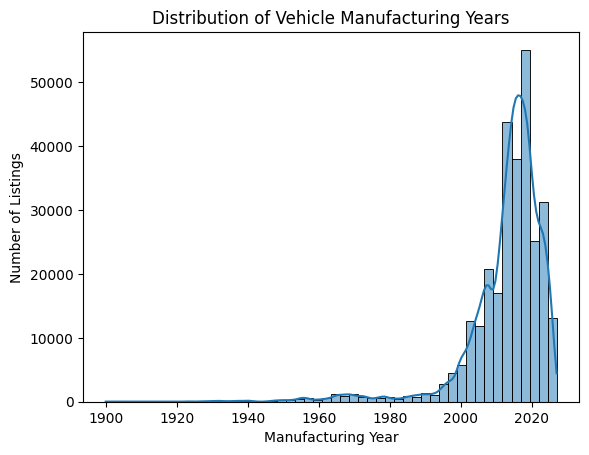

In [5]:
sns.histplot(
    df['year'].dropna(),
    bins=50,
    kde=True
)

plt.title('Distribution of Vehicle Manufacturing Years')
plt.xlabel('Manufacturing Year')
plt.ylabel('Number of Listings')

plt.show()

In [6]:
df.loc[
    df['year'] < 1950,
    ['year', 'manufacturer', 'model', 'price', 'title']
].head(5)

,year,manufacturer,model,price,title
779,1932.0,ford,t bucket,11000,Ford T bucket hot rod project
935,1923.0,ford,bucket-t,25000,1923 Ford Bucket‑T – Auto – 6692 Miles – Clean...
1608,1935.0,NaN,Studebaker Dictator,36995,1935 Studebaker Dictator 4DR ~ L@@K ~ What A C...
2073,1939.0,ford,1/2 ton pickup,19950,Vintage 1939 Ford 1/2 Ton Pickup
2099,1920.0,ford,model t,14000,Model T Speedster


In [7]:
df.loc[
    df['year'] >2026,
    ['year', 'manufacturer', 'model', 'price', 'title']
].head(5)

,year,manufacturer,model,price,title
456,2027.0,ford,expedition max platinum,1658,"2027 Ford Expedition Max Platinum FOR ONLY $1,..."
577,2027.0,toyota,corolla le,0,2027 Toyota Corolla LE sedan Ice Cap
583,2027.0,toyota,corolla le,0,2027 Toyota Corolla LE sedan Celestite
606,2027.0,toyota,camry se,0,2027 Toyota Camry SE sedan Supersonic Red <a
857,2027.0,ford,super duty f-350 srw xl,1092,2027 Ford Super Duty F350 F 350 F-350 SRW Supe...


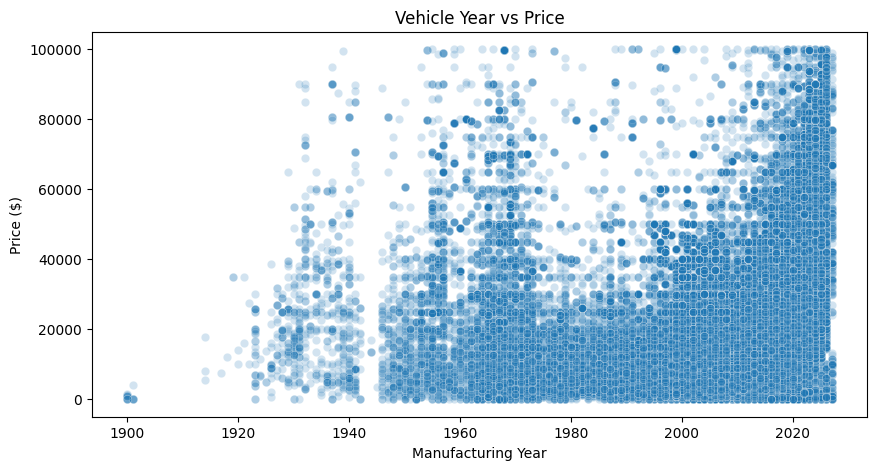

In [8]:
price_numeric=pd.to_numeric(df['price'],errors='coerce')

data=df.loc[
    (df['year'].notna())& (price_numeric>0)
].copy()
data['price']=price_numeric.loc[data.index]
data=data[data['price']<=100000]

plt.figure(figsize=(10, 5))
sns.scatterplot(data=data, x='year', y='price', alpha=0.2)

plt.title('Vehicle Year vs Price')
plt.xlabel('Manufacturing Year')
plt.ylabel('Price ($)')
plt.show()

In [9]:
data[['year', 'price']].corr()

,year,price
year,1.00000,0.19783
price,0.19783,1.00000


- Manufacturing year may help predict vehicle prices, but it is not sufficient on its own. Other features such as manufacturer, model, mileage and condition should also be investigated.

# odometer data quality check 

In [22]:
temp = df.copy()
temp['price_numeric'] = price_numeric
temp = temp[temp['price_numeric'] > 0]

plot_df = temp[(temp['price_numeric'] <= 100000) & (temp['odometer'] <= 500000)]

In [23]:
plot_df['odometer'].describe()

count    279036.000000
mean     111484.502964
std       61574.371417
min           1.000000
25%       69545.750000
50%      108881.000000
75%      148117.750000
max      500000.000000
Name: odometer, dtype: float64

<Axes: xlabel='odometer', ylabel='Count'>

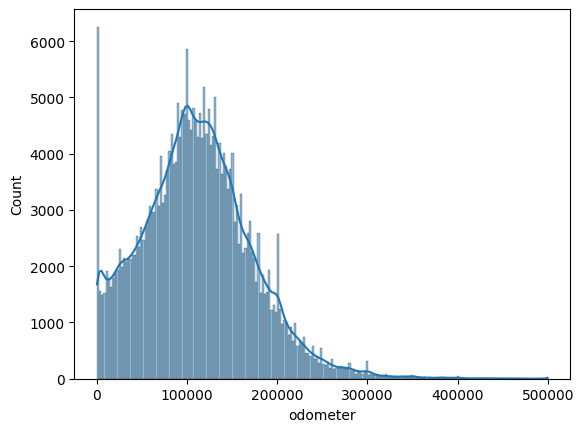

In [24]:
sns.histplot(plot_df['odometer'], kde=True)

In [25]:
plot_df['odometer'].skew()

np.float64(0.5930286925996151)

<Axes: ylabel='odometer'>

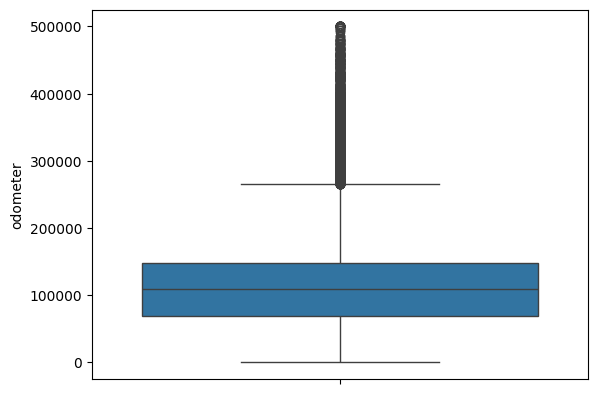

In [26]:
sns.boxplot(plot_df['odometer'])

<Axes: xlabel='odometer', ylabel='price_numeric'>

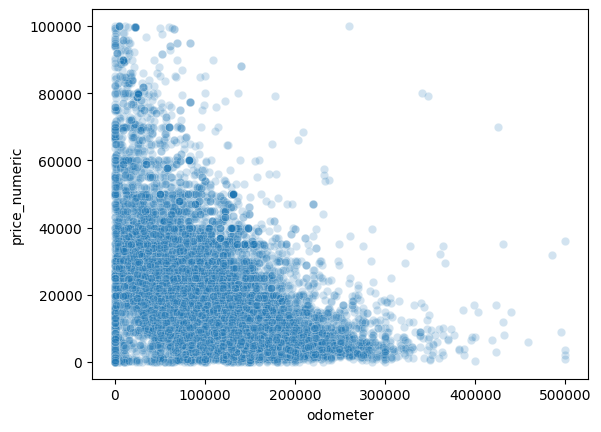

In [27]:
sample_df = plot_df.sample(20000, random_state=42)
sns.scatterplot(x=sample_df['odometer'], y=sample_df['price_numeric'], alpha=0.2)

In [28]:
plot_df[['odometer', 'price_numeric']].corr()

,odometer,price_numeric
odometer,1.000000,-0.482703
price_numeric,-0.482703,1.000000


In [29]:
plot_df[['year', 'odometer', 'price_numeric']].corr(method='spearman')

,year,odometer,price_numeric
year,1.000000,-0.431845,0.525797
odometer,-0.431845,1.000000,-0.543951
price_numeric,0.525797,-0.543951,1.000000


- Year’s Pearson correlation with price is only 0.19, but its Spearman correlation is 0.53. The relationship is strong but not linear, likely because vintage cars are old yet expensive. Odometer is similar under both measures (Pearson -0.48, Spearman -0.54). Year and odometer correlate at -0.43 with each other, so they’re related but each adds information.

# Duplicates

In [30]:
df.duplicated().sum()

np.int64(0)

In [31]:
df['id'].duplicated().sum()

np.int64(0)

In [32]:
df['VIN'].value_counts().head(10)

VIN
1FTNW21FXYED30441    167
1FTHF26G7VEA77606    159
1B7KF26C6SS150366    150
1FTNW21F1YEA14829    131
1FTWX33F9YEA12508    130
1GYS4GKL2RR104604    126
1D7KS28C26J203560    121
3D7LX38C36G177354    121
1FTHX26F6TEA44954    121
1GKS2DKT2NR136641    120
Name: count, dtype: int64

In [33]:
df.duplicated(subset=['year', 'manufacturer', 'model', 'odometer', 'price', 'state']).sum()

np.int64(84843)

In [34]:
subset = ['year', 'manufacturer', 'model', 'odometer', 'price', 'state']
dups = df[df.duplicated(subset=subset, keep=False)]
len(dups)

126180

In [35]:
dups[subset].isnull().any(axis=1).sum()

np.int64(6870)

In [36]:
(dups['odometer'] < 100).sum()

np.int64(1523)

In [37]:
complete = df.dropna(subset=subset)
complete.duplicated(subset=subset).sum()

np.int64(80208)

In [38]:
df['VIN'].dropna().duplicated().sum()

np.int64(84239)

- There are cars which are posted more than once on list .
- About 80,208 rows have exact same year,brand ,model,mileage,price and state .
- About 84239 rows have a VIN (the car’s unique ID number) that already appeared earlier.
- that means our data have duplicates.